In [4]:
print("Hello World")

Hello World


In [5]:

# Cell 1: Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [6]:

# Cell 2: Load dataset

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)
print("Number of classes:", len(np.unique(y_train)))


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Number of classes: 10


In [7]:

# Cell 2: Load dataset

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)
print("Number of classes:", len(np.unique(y_train)))


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Number of classes: 10


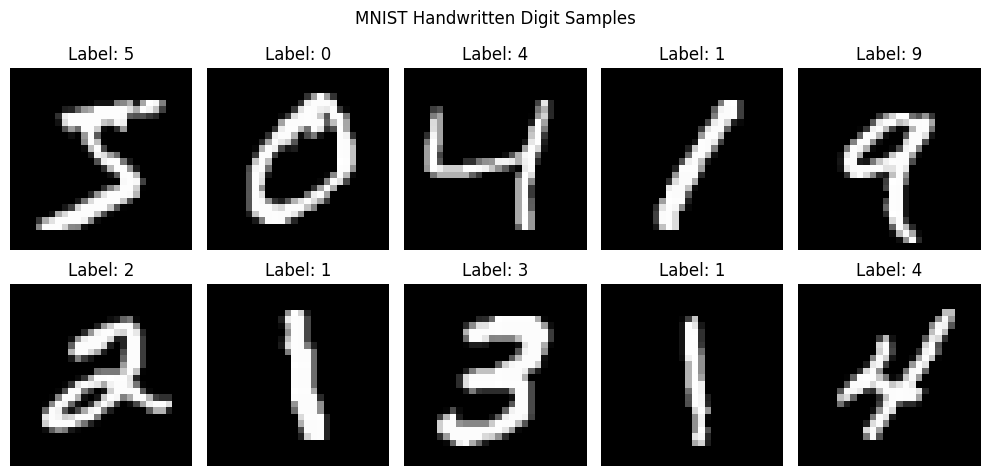

In [8]:

# Cell 3: Visualize the dataset

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("MNIST Handwritten Digit Samples")
plt.tight_layout()
plt.show()


In [9]:

# Cell 4: Normalize and reshape images

# Normalize pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# CNN requires a channel dimension for grayscale images
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Processed training shape:", x_train.shape)
print("Processed testing shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Processed training shape: (60000, 28, 28, 1)
Processed testing shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [10]:

# Cell 5: Create CNN model

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:

# Cell 6: Train CNN

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("Model training completed!")


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 103ms/step - accuracy: 0.9169 - loss: 0.2706 - val_accuracy: 0.9797 - val_loss: 0.0691
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9763 - loss: 0.0781 - val_accuracy: 0.9882 - val_loss: 0.0452
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9828 - loss: 0.0558 - val_accuracy: 0.9883 - val_loss: 0.0406
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 84s 103ms/step - accuracy: 0.9862 - loss: 0.0441 - val_accuracy: 0.9897 - val_loss: 0.0383
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 98ms/step - accuracy: 0.9886 - loss: 0.0353 - val_accuracy: 0.9908 - val_loss: 0.0358
Model training completed!


In [12]:

# Cell 7: Evaluate on test dataset

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("\nMODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-Score:   {f1:.4f}")



MODEL EVALUATION RESULTS
-----------------------------------
Test Loss:  0.0327
Accuracy:   0.9898 (98.98%)
Precision:  0.9897
Recall:     0.9897
F1-Score:   0.9897


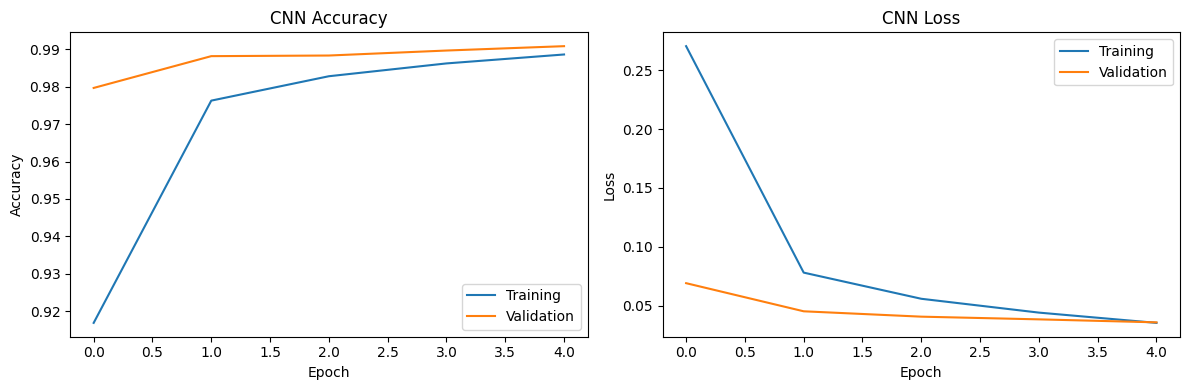

In [13]:

# Cell 8: Training performance graphs

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       1.00      0.99      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.98      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       1.00      0.98      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



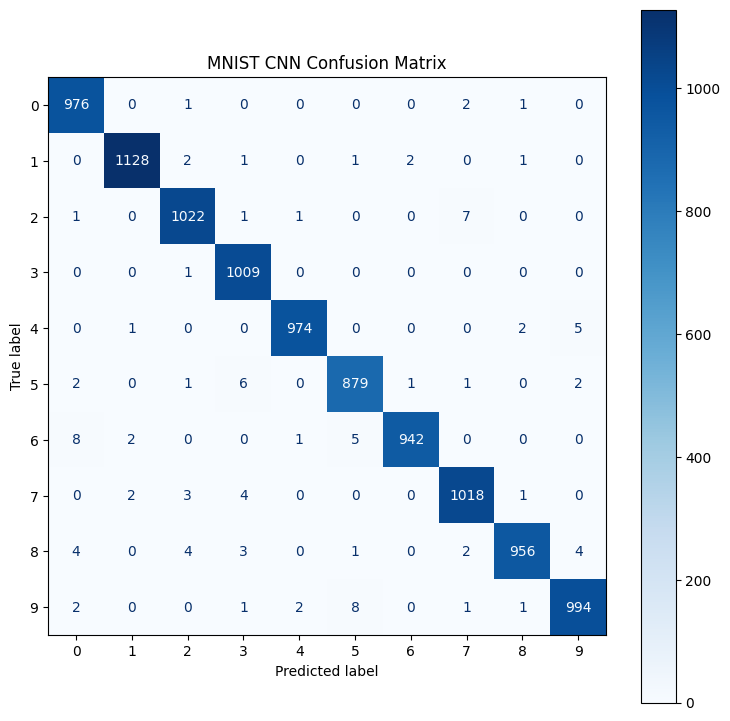

In [14]:

# Cell 9: Detailed classification results

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=[str(i) for i in range(10)],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("MNIST CNN Confusion Matrix")
plt.show()


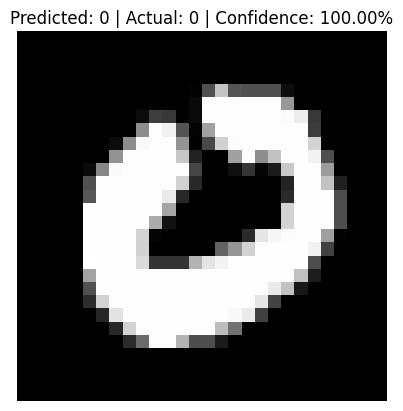

Predicted digit: 0
Actual digit: 0
Confidence: 100.00%


In [15]:

# Cell 10: Test a sample image

index = 25

image = x_test[index]
prediction = model.predict(
    np.expand_dims(image, axis=0), verbose=0
)[0]

predicted_digit = int(np.argmax(prediction))
confidence = float(np.max(prediction)) * 100

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {predicted_digit} | "
    f"Actual: {y_test[index]} | "
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[index])
print(f"Confidence: {confidence:.2f}%")


In [18]:

# Cell 11: Upload and predict your own digit

from google.colab import files
from PIL import Image, ImageOps, UnidentifiedImageError
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded.keys():
    try:
        img = Image.open(filename).convert("L")

        # Convert white background / dark writing
        # to MNIST-style black background / white writing
        img = ImageOps.invert(img)
        img = img.resize((28, 28))

        img_array = np.array(img).astype("float32") / 255.0
        img_array = img_array.reshape(1, 28, 28, 1)

        probabilities = model.predict(img_array, verbose=0)[0]
        digit = int(np.argmax(probabilities))
        confidence = float(np.max(probabilities)) * 100

        plt.figure(figsize=(3, 3))
        plt.imshow(img_array[0, :, :, 0], cmap="gray")
        plt.title(f"Predicted digit: {digit}")
        plt.axis("off")
        plt.show()

        print("Uploaded file:", filename)
        print("Predicted digit:", digit)
        print(f"Confidence: {confidence:.2f}%")
    except UnidentifiedImageError:
        print(f"\nError: '{filename}' is not a valid image file. Please upload a .png, .jpg, or .jpeg file instead.")


Saving handwritten_digit_cnn.keras to handwritten_digit_cnn (1).keras

Error: 'handwritten_digit_cnn (1).keras' is not a valid image file. Please upload a .png, .jpg, or .jpeg file instead.


In [17]:

# Cell 12: Save model

model.save("handwritten_digit_cnn.keras")

print("Model saved successfully!")

# Download model to your computer
from google.colab import files
files.download("handwritten_digit_cnn.keras")


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>